# Questions 2.1 to 2.8

### Imports

In [1]:
import config as cfg
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import src.loading as ld
import src.normalise as norm
import src.features as ftrs

### Loading DataSet
No test actors included

In [2]:
df = ld.load_frames()
df.shape

(132176, 147)

## Q2.1

### Normalising DataSet

#### Using inter-ocular distance

In [3]:
df_d = norm.normalise_d(df)
df_d.shape

(132176, 147)

#### Sanity Check 

In [4]:
print("x_27 and y_27 == 0\n" if (df_d[["x_27", "y_27"]] == 0).all().all() else "Error: x_27 and y_27 != 0\n")

distance = ftrs.euclidean_distance(df_d, 36, 45)
if np.allclose(distance, 1):
    print("Distance between landmarks 36 and 45 are all 1\n")
else:
    print("Error: Distance between landmarks 36 and 45 are not all 1\n")

if np.isnan(df_d[norm.X_COLS + norm.Y_COLS]).any().any():
    print("Error: There are NaNs in the coordinates columns")
else:
    print("There are no NaNs in the coordinates columns")

x_27 and y_27 == 0

Distance between landmarks 36 and 45 are all 1

There are no NaNs in the coordinates columns


#### Using dimensions of the image

In [5]:
df_image = norm.normalise_image(df)
df_image.shape

(132176, 147)

#### Sanity Check

In [6]:
print("x_27 and y_27 == 0\n" if (df_image[["x_27", "y_27"]] == 0).all().all() else "Error: x_27 and y_27 != 0\n")

if np.isnan(df_image[norm.X_COLS + norm.Y_COLS]).any().any():
    print("Error: There are NaNs in the coordinates columns")
else:
    print("There are no NaNs in the coordinates columns")

x_27 and y_27 == 0

There are no NaNs in the coordinates columns


### Neutral Emotion

In [12]:
df_neutral = df[df["emotion"] == 1]
df_d_neutral = df_d[df_d["emotion"] == 1]
df_image_neutral = df_image[df_image["emotion"] == 1]

print(f"Number of unique videos in:\n df_neutral: {df_neutral['video_id'].nunique()}\n df_d_neutral: {df_d_neutral['video_id'].nunique()}\n df_image_neutral: {df_image_neutral['video_id'].nunique()}")

print(f"Number of unique actors in:\n df_neutral: {df_neutral['actor'].nunique()}\n df_d_neutral: {df_d_neutral['actor'].nunique()}\n df_image_neutral: {df_image_neutral['actor'].nunique()}")

Number of unique videos in:
 df_neutral: 80
 df_d_neutral: 80
 df_image_neutral: 80
Number of unique actors in:
 df_neutral: 20
 df_d_neutral: 20
 df_image_neutral: 20


#### Mouth width per frame

In [8]:
df_widths = pd.DataFrame({
    "actor": df_neutral["actor"],
    "raw": ftrs.euclidean_distance(df_neutral, 48, 54),
    "inter-ocular": ftrs.euclidean_distance(df_d_neutral, 48, 54),
    "image": ftrs.euclidean_distance(df_image_neutral, 48, 54),
})

df_widths

,actor,raw,inter-ocular,image
0,2,114.377139,0.568433,0.089487
1,2,114.784363,0.569890,0.089818
2,2,114.788240,0.569900,0.089827
3,2,114.780573,0.568761,0.089808
4,2,114.684437,0.568567,0.089740
...,...,...,...,...
8342,23,132.274903,0.640931,0.103634
8343,23,132.973982,0.643086,0.104179
8344,23,133.673071,0.647079,0.104724
8345,23,133.857910,0.647386,0.104843


#### Median of mouth width per actor

In [9]:
median_widths = df_widths.groupby("actor").median()
median_widths

,raw,inter-ocular,image
actor,,,
2,115.387954,0.566075,0.090233
3,124.821232,0.624451,0.097635
4,122.262218,0.611065,0.095907
5,139.316600,0.619302,0.108878
6,123.227310,0.615028,0.096501
7,133.503034,0.637391,0.104304
8,120.730195,0.613624,0.094383
9,122.382760,0.569194,0.095751
10,122.277430,0.591432,0.095975


#### Coeficient of Variation

In [10]:
cv = (median_widths.std() / median_widths.mean()).rename("CV").to_frame()
cv.index.name = "normalisation"
cv


,CV
normalisation,
raw,0.078814
inter-ocular,0.045567
image,0.078502


#### Plotting actors per normalisation

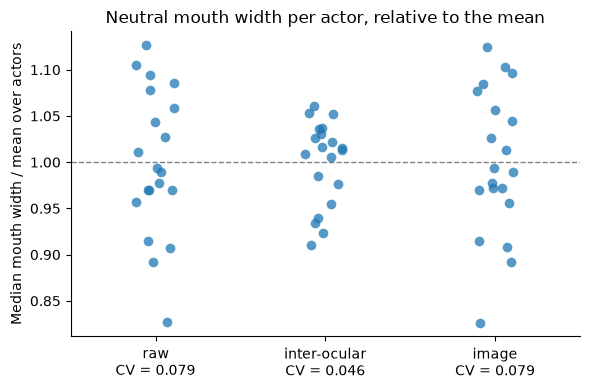

In [11]:
medians_rel = median_widths / median_widths.mean()

long = medians_rel.melt(var_name="normalisation", value_name="relative_width")

fig, ax = plt.subplots(figsize=(6, 4))
ax.axhline(1, color="grey", linestyle="--", linewidth=1, zorder=0)
sns.stripplot(data=long, x="normalisation", y="relative_width", jitter=0.12, size=7, alpha=0.75, color="tab:blue", ax=ax)
ax.set_xticks(range(len(cv)))
ax.set_xticklabels([f"{name}\nCV = {value:.3f}" for name, value in cv["CV"].items()])
ax.set_xlabel("")
ax.set_ylabel("Median mouth width / mean over actors")
ax.set_title("Neutral mouth width per actor, relative to the mean")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()


The "raw" and "image" columns show the same spread, while the "inter-ocular" column shows a much tighter spread.

### Answer to Q2.1

## Normalisation

## Inter-ocular distance 
Leaves less variation between actors, the coefficient of variation of the 20 median neutral mouth widths is 0.046, against 0.079 for the normalisation by the image dimensions

The distance d is computed in each frame and scales with the apparent size of the face, so dividing by it expresses every coordinate in units of the inter-ocular distance.
Actors such as 5 and 11 have wide mouths in pixels but are close to the mean once divided by d. 
The variation that remains reflects real differences in facial proportions between people, which is good since it is what a normalisation should achieve.

## Image normalisation
Does not reduce the variation at all, its CV is practically the same as raw. 
The CV is a ratio of standard deviation to mean, so dividing every actor by the same constants leaves it unchanged.
The small difference comes only from x and y being divided by different constants.
Actors still differ in how large their face appears in the image, because of their distance to the camera and the size of their head.

Dividing x by 1280 and y by 720 also distorts the geometry of the face. The two axes are scaled by different factors, so the face is stretched vertically by 1280/720 ≈ 1.78 relative to its width. 
A distance then depends on its orientation, angles are not preserved, and tilting the head changes the measurements. The result also depends on the resolution of the camera.

> All the remaining tasks use the normalisation by d.
